In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")

DATA_DIR = Path("../dataset")
REPORT_DIR = Path("../reports")
VIS_DIR = Path("../visualizations")

REPORT_DIR.mkdir(parents=True, exist_ok=True)
VIS_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_DIR / "steam_games_enriched.csv")

display(df.head())


,name,release_date,estimated_owners,price,positive,negative,average_playtime_forever,genres,total_reviews,positive_rate,negative_rate,release_year,price_category,estimated_owners_midpoint,game_performance_category
0,Shadow Empire Deluxe 2049,2013-05-17,"0 .. 20,000",5.99,629.0,163.0,171.0,"Indie, Horror",792.0,79.419192,20.580808,2013.0,Budget,10000.0,Hidden Gem
1,Crimson Rift Origins,2013-06-12,"100,000 .. 200,000",0.99,6293.0,23.0,NaN,Free To Play,6316.0,99.635845,0.364155,2013.0,Budget,150000.0,Hidden Gem
2,Forgotten Legends,2012-04-14,"10,000,000 .. 20,000,000",14.99,690.0,76.0,152.0,Strategy,766.0,90.078329,9.921671,2012.0,Mid-range,15000000.0,Top Performer
3,Last Empire Origins,2012-03-25,"20,000 .. 50,000",4.99,19009.0,486.0,43.0,"Puzzle, Sports",19495.0,97.507053,2.492947,2012.0,Budget,35000.0,Hidden Gem
4,Iron Tactics Deluxe 2,2009-05-24,"20,000 .. 50,000",59.99,3820.0,163.0,181.0,"Sports, Puzzle",3983.0,95.907607,4.092393,2009.0,Premium,35000.0,Hidden Gem


### Question 1. Which 10 games have the highest total reviews?

,name,total_reviews,positive,negative
113,Shadow Arena,33737.0,33679.0,58.0
141,Neon Empire Remastered,33570.0,33412.0,158.0
240,Lost Empire Online,32995.0,32863.0,132.0
15,Pixel Tactics Remastered,32862.0,32785.0,77.0
238,Shadow Empire,27156.0,27018.0,138.0
239,PIXEL SURVIVAL DELUXE,23806.0,23709.0,97.0
117,Iron Rift Deluxe,23504.0,23474.0,30.0
164,Frozen Rift Reborn,20744.0,20686.0,58.0
163,Shadow Odyssey Origins,20575.0,19493.0,1082.0
363,Lost Journey Remastered,20125.0,20055.0,70.0


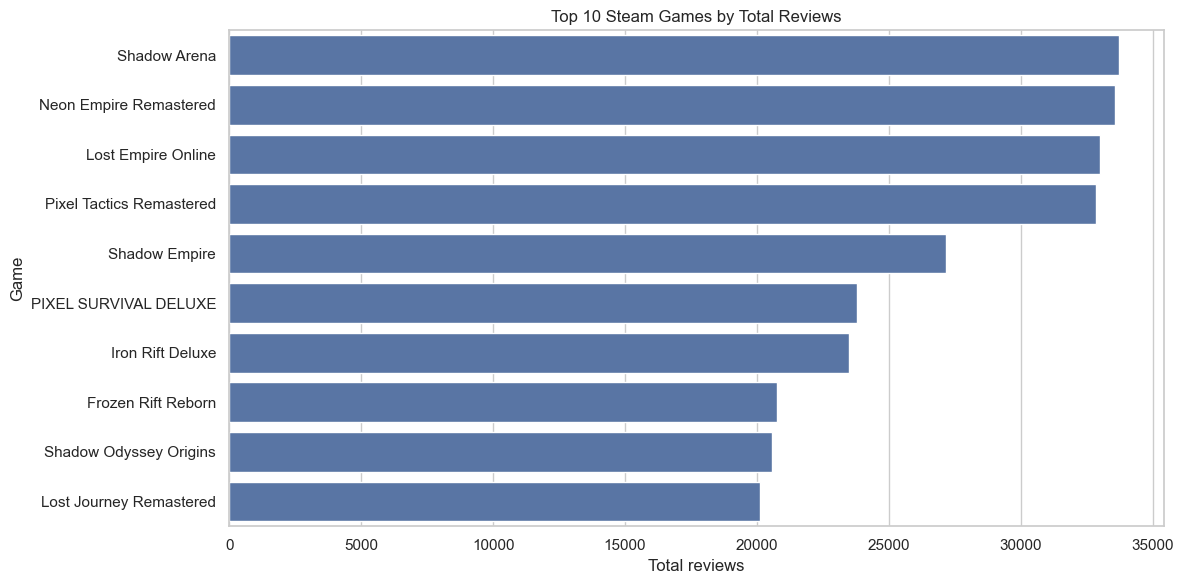

In [2]:
top_reviewed_games = (
    df.dropna(subset=["total_reviews"])
      .nlargest(10, "total_reviews")[["name", "total_reviews", "positive", "negative"]]
)

display(top_reviewed_games)

plt.figure(figsize=(12, 6))
sns.barplot(data=top_reviewed_games, x="total_reviews", y="name")
plt.title("Top 10 Steam Games by Total Reviews")
plt.xlabel("Total reviews")
plt.ylabel("Game")
plt.tight_layout()
plt.savefig(VIS_DIR / "top_10_reviewed_games.png", dpi=300, bbox_inches="tight")
plt.show()

top_reviewed_games.to_csv(REPORT_DIR / "top_10_reviewed_games.csv", index=False)


### Question 2: Which games have the highest estimated ownership?

,name,estimated_owners,estimated_owners_midpoint
2,Forgotten Legends,"10,000,000 .. 20,000,000",15000000.0
64,Tiny Simulator Deluxe,"10,000,000 .. 20,000,000",15000000.0
67,Forgotten Legends Deluxe,"10,000,000 .. 20,000,000",15000000.0
73,Wild Empire Reborn,"10,000,000 .. 20,000,000",15000000.0
87,Pixel Survival Deluxe,"10,000,000 .. 20,000,000",15000000.0
89,Baldur's Gate 3,"10,000,000 .. 20,000,000",15000000.0
109,Cyber Journey Online,"10,000,000 .. 20,000,000",15000000.0
112,Euro Truck Simulator 2,"10,000,000 .. 20,000,000",15000000.0
117,Iron Rift Deluxe,"10,000,000 .. 20,000,000",15000000.0
141,Neon Empire Remastered,"10,000,000 .. 20,000,000",15000000.0


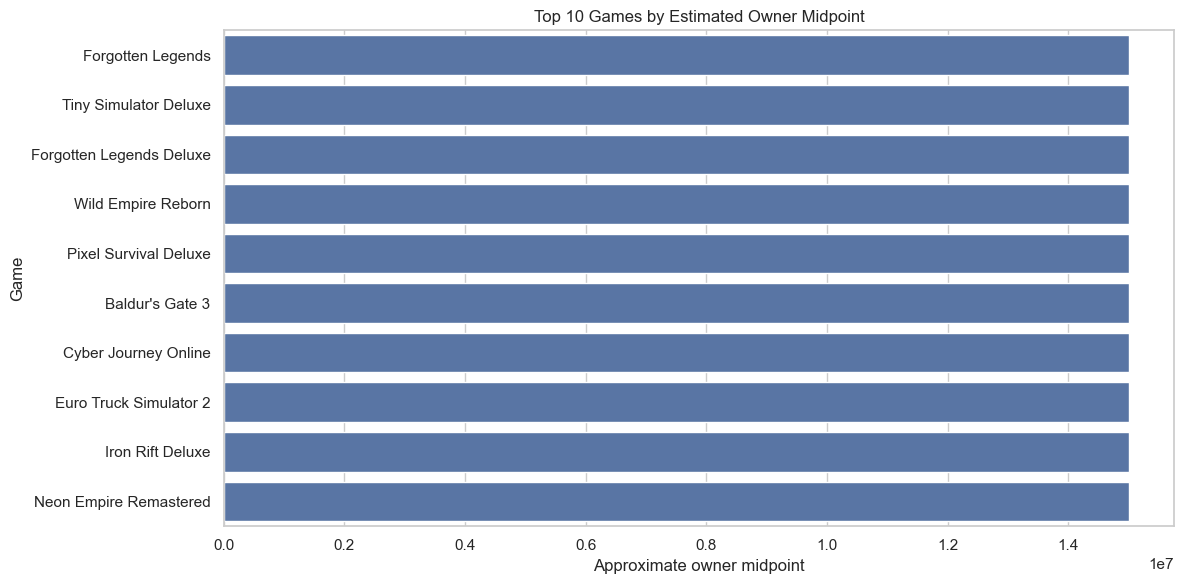

In [3]:
top_owned_games = (
    df.dropna(subset=["estimated_owners_midpoint"])
      .nlargest(10, "estimated_owners_midpoint")
      [["name", "estimated_owners", "estimated_owners_midpoint"]]
)
display(top_owned_games)

plt.figure(figsize=(12, 6))
sns.barplot(data=top_owned_games, x="estimated_owners_midpoint", y="name")
plt.title("Top 10 Games by Estimated Owner Midpoint")
plt.xlabel("Approximate owner midpoint")
plt.ylabel("Game")
plt.tight_layout()
plt.savefig(VIS_DIR / "top_10_owned_games.png", dpi=300, bbox_inches="tight")
plt.show()


### Question 3: What is the overall player satisfaction rate?

Overall positive review rate: 91.58%


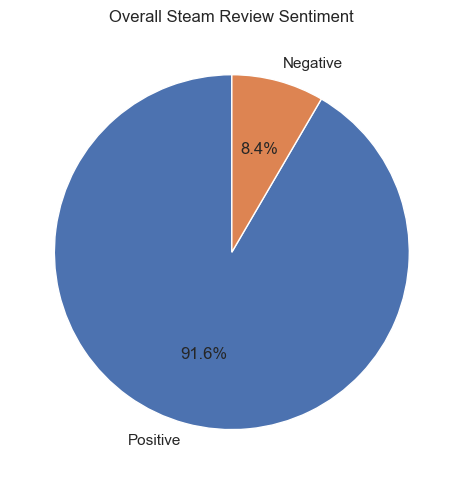

In [4]:
positive_total = df["positive"].sum(min_count=1)
negative_total = df["negative"].sum(min_count=1)
review_total = positive_total + negative_total

overall_positive_rate = (
    positive_total / review_total * 100 if review_total > 0 else np.nan
)
print(f"Overall positive review rate: {overall_positive_rate:.2f}%")

plt.figure(figsize=(6, 5))
plt.pie(
    [positive_total, negative_total],
    labels=["Positive", "Negative"],
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Overall Steam Review Sentiment")
plt.tight_layout()
plt.savefig(VIS_DIR / "overall_review_sentiment.png", dpi=300, bbox_inches="tight")
plt.show()


### Question 4: Which games have the highest positive review rate?

,name,positive_rate,total_reviews
74,mystic rift remastered,99.901551,8126.0
117,Iron Rift Deluxe,99.872362,23504.0
113,Shadow Arena,99.828082,33737.0
348,Mystic Odyssey Reborn,99.801356,14599.0
15,Pixel Tactics Remastered,99.765687,32862.0
173,Iron Empire Deluxe,99.759230,1246.0
420,Tiny Protocol Reborn,99.737073,11410.0
164,Frozen Rift Reborn,99.720401,20744.0
250,Wild Dungeon Deluxe,99.707505,11966.0
457,RESIDENT EVIL 4,99.665989,6886.0


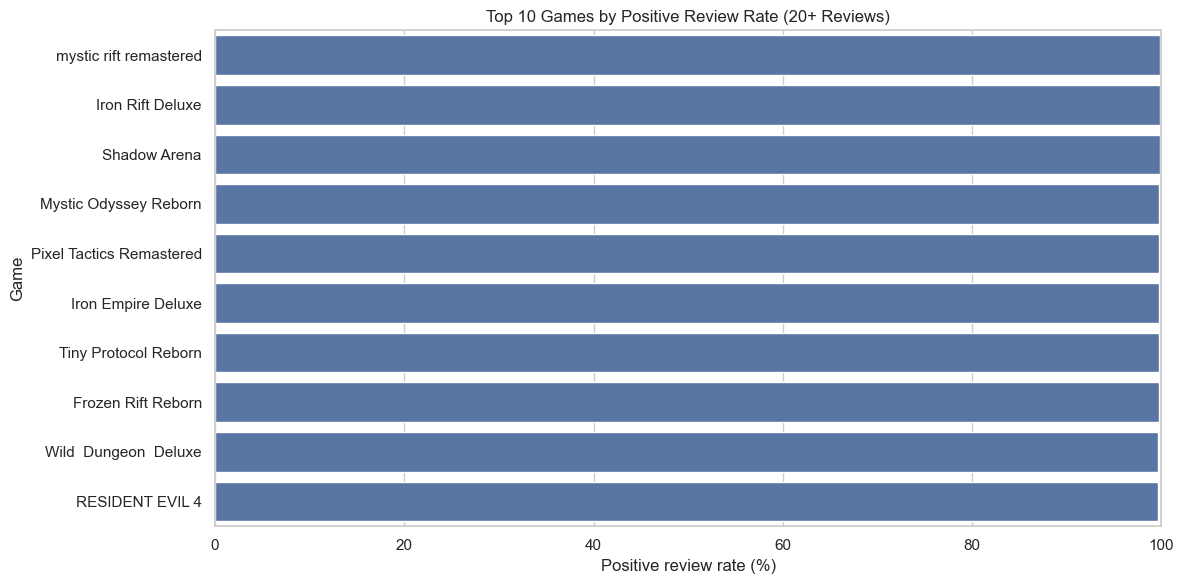

In [5]:
best_rated_games = (
    df[df["total_reviews"].ge(20)]
      .dropna(subset=["positive_rate"])
      .nlargest(10, "positive_rate")[["name", "positive_rate", "total_reviews"]]
)
display(best_rated_games)

plt.figure(figsize=(12, 6))
sns.barplot(data=best_rated_games, x="positive_rate", y="name")
plt.title("Top 10 Games by Positive Review Rate (20+ Reviews)")
plt.xlabel("Positive review rate (%)")
plt.ylabel("Game")
plt.xlim(0, 100)
plt.tight_layout()
plt.savefig(VIS_DIR / "top_positive_rate_games.png", dpi=300, bbox_inches="tight")
plt.show()


### Question 5: What is the distribution of price categories?

,game_count
price_category,
Free,34
Budget,212
Mid-range,132
Premium,98
Unknown,15


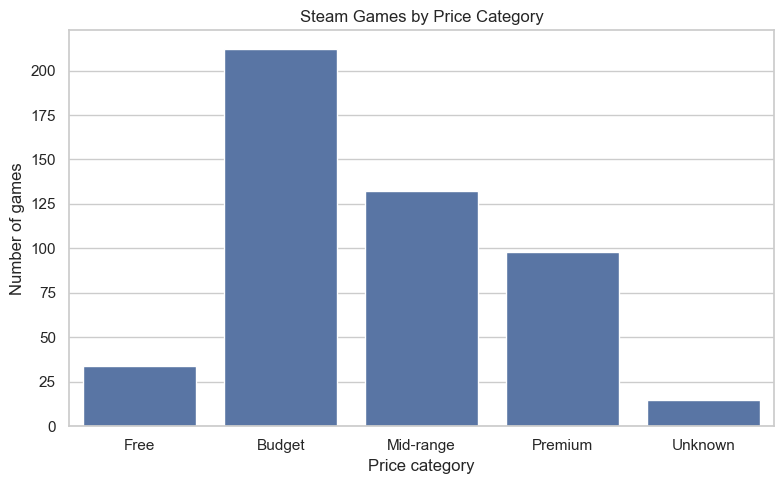

In [6]:
price_counts = df["price_category"].value_counts().reindex(
    ["Free", "Budget", "Mid-range", "Premium", "Unknown"], fill_value=0
)
display(price_counts.to_frame("game_count"))

plt.figure(figsize=(8, 5))
sns.barplot(x=price_counts.index, y=price_counts.values)
plt.title("Steam Games by Price Category")
plt.xlabel("Price category")
plt.ylabel("Number of games")
plt.tight_layout()
plt.savefig(VIS_DIR / "price_category_distribution.png", dpi=300, bbox_inches="tight")
plt.show()


### Question 6: Which genres appear most often?

,game_count
genre,
Free To Play,96
Puzzle,96
Strategy,95
Racing,90
Adventure,90
Platformer,84
Massively Multiplayer,83
Action,81
Casual,78


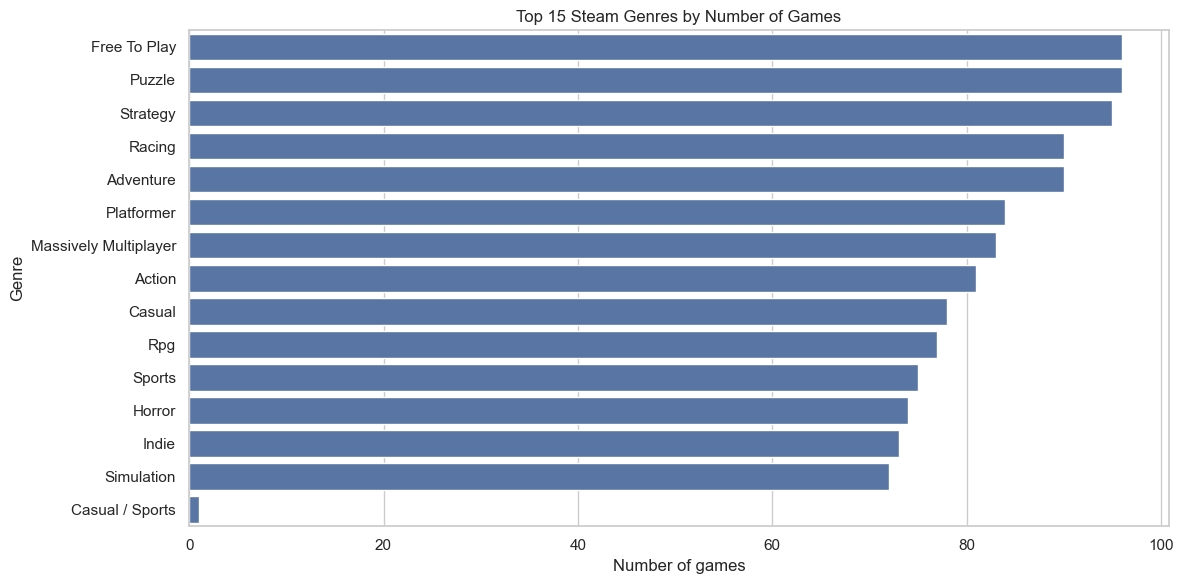

In [7]:
genre_df = (
    df.dropna(subset=["genres"])
      .assign(genre=df["genres"].str.split(", "))
      .explode("genre")
)
genre_counts = genre_df["genre"].value_counts().head(15)
display(genre_counts.to_frame("game_count"))

plt.figure(figsize=(12, 6))
sns.barplot(x=genre_counts.values, y=genre_counts.index)
plt.title("Top 15 Steam Genres by Number of Games")
plt.xlabel("Number of games")
plt.ylabel("Genre")
plt.tight_layout()
plt.savefig(VIS_DIR / "top_genres.png", dpi=300, bbox_inches="tight")
plt.show()


### Question 7: Which genres have the highest average player satisfaction?

,average_positive_rate,games,total_reviews
genre,,,
Casual,86.768267,74,266280.0
Racing,86.760313,89,345799.0
Sports,85.157537,75,250296.0
Massively Multiplayer,85.007345,82,367489.0
Rpg,84.747583,74,217799.0
Strategy,84.542413,93,305985.0
Simulation,83.964298,69,167103.0
Adventure,83.748731,87,376479.0
Free To Play,83.057808,96,337037.0


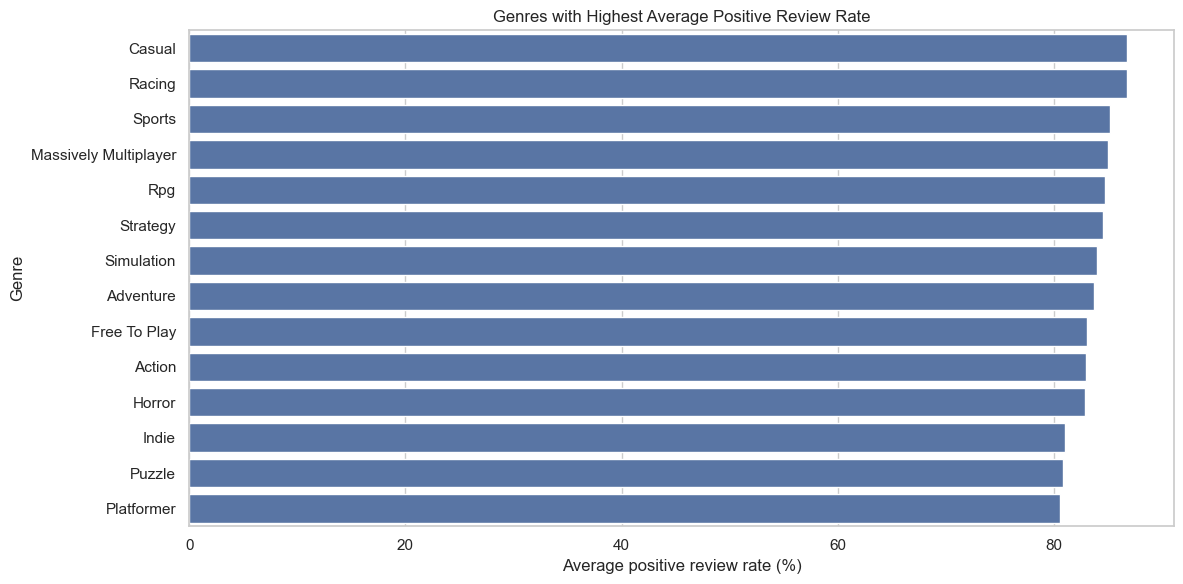

In [8]:
genre_satisfaction = (
    genre_df.groupby("genre")
    .agg(
        average_positive_rate=("positive_rate", "mean"),
        games=("name", "nunique"),
        total_reviews=("total_reviews", "sum")
    )
    .query("games >= 3 and total_reviews >= 20")
    .sort_values("average_positive_rate", ascending=False)
    .head(15)
)
display(genre_satisfaction)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=genre_satisfaction.reset_index(),
    x="average_positive_rate",
    y="genre"
)
plt.title("Genres with Highest Average Positive Review Rate")
plt.xlabel("Average positive review rate (%)")
plt.ylabel("Genre")
plt.tight_layout()
plt.savefig(VIS_DIR / "genre_satisfaction.png", dpi=300, bbox_inches="tight")
plt.show()


### Question 8: Which games have the highest average playtime?

,name,average_playtime_forever,total_reviews
440,Forza Horizon 5,16140.0,527.0
9,Silent Legends Deluxe,13920.0,1849.0
281,Iron Dungeon Online,12960.0,NaN
399,Tiny Arena Reborn,9440.0,2813.0
154,Forgotten Chronicles Reborn,7500.0,13793.0
349,Wild Journey Online,3041.0,8350.0
422,Cyber Dungeon Origins,2786.0,NaN
81,Project Zomboid,2352.0,1454.0
56,BEYOND ARENA ONLINE,2311.0,1940.0
145,Iron Chronicles Reborn,1905.0,4799.0


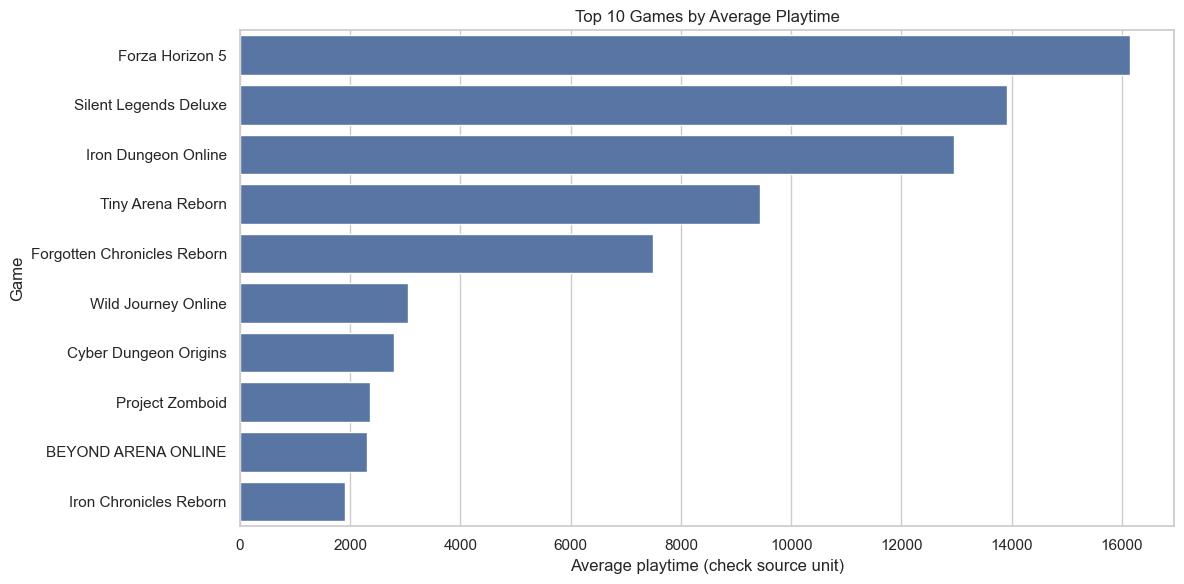

In [9]:
top_playtime_games = (
    df.dropna(subset=["average_playtime_forever"])
      .nlargest(10, "average_playtime_forever")
      [["name", "average_playtime_forever", "total_reviews"]]
)
display(top_playtime_games)

plt.figure(figsize=(12, 6))
sns.barplot(data=top_playtime_games, x="average_playtime_forever", y="name")
plt.title("Top 10 Games by Average Playtime")
plt.xlabel("Average playtime (check source unit)")
plt.ylabel("Game")
plt.tight_layout()
plt.savefig(VIS_DIR / "top_playtime_games.png", dpi=300, bbox_inches="tight")
plt.show()


### Question 9: Is playtime related to player satisfaction?

Pearson correlation: -0.068


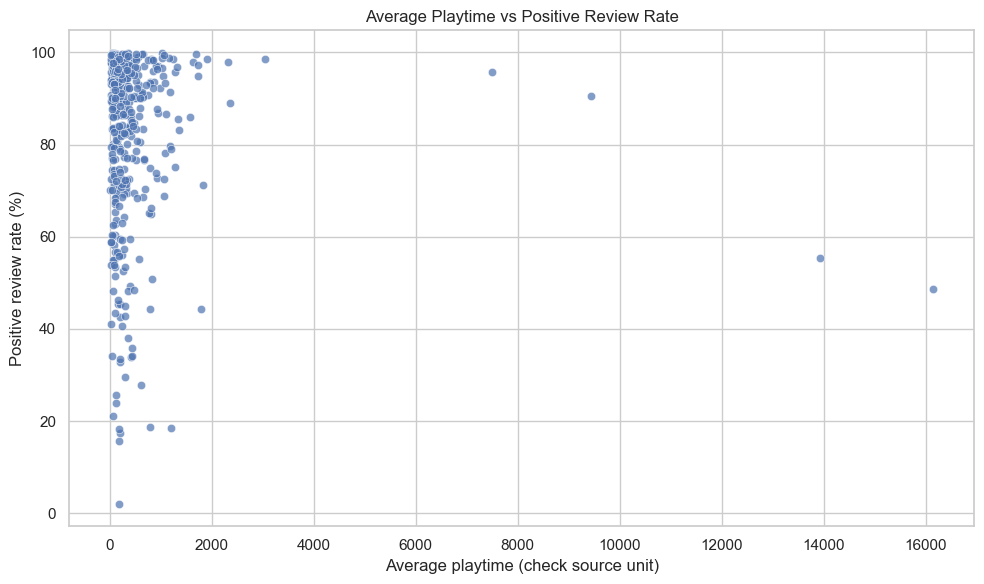

In [10]:
relationship_df = df.dropna(
    subset=["average_playtime_forever", "positive_rate"]
).copy()

if len(relationship_df) >= 2:
    correlation = relationship_df[
        ["average_playtime_forever", "positive_rate"]
    ].corr(method="pearson").iloc[0, 1]
    print(f"Pearson correlation: {correlation:.3f}")
else:
    print("Not enough complete rows to calculate correlation.")

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=relationship_df,
    x="average_playtime_forever",
    y="positive_rate",
    alpha=0.7
)
plt.title("Average Playtime vs Positive Review Rate")
plt.xlabel("Average playtime (check source unit)")
plt.ylabel("Positive review rate (%)")
plt.tight_layout()
plt.savefig(VIS_DIR / "playtime_vs_satisfaction.png", dpi=300, bbox_inches="tight")
plt.show()


### Question 10: Which games are hidden gems?

In [11]:
hidden_gems = (
    df[df["game_performance_category"].eq("Hidden Gem")]
      .sort_values(["positive_rate", "total_reviews"], ascending=False)
      [["name", "positive_rate", "total_reviews", "estimated_owners_midpoint",
        "price", "genres"]]
)
display(hidden_gems.head(20))
hidden_gems.to_csv(REPORT_DIR / "hidden_gems.csv", index=False)


,name,positive_rate,total_reviews,estimated_owners_midpoint,price,genres
113,Shadow Arena,99.828082,33737.0,35000.0,9.99,"Adventure, Racing, Casual"
348,Mystic Odyssey Reborn,99.801356,14599.0,75000.0,24.99,"Racing, Strategy"
15,Pixel Tactics Remastered,99.765687,32862.0,350000.0,2.69,"Sports, Strategy"
420,Tiny Protocol Reborn,99.737073,11410.0,350000.0,24.99,"Puzzle, Sports"
164,Frozen Rift Reborn,99.720401,20744.0,75000.0,4.99,"Horror, Simulation"
250,Wild Dungeon Deluxe,99.707505,11966.0,35000.0,14.99,"Rpg, Simulation, Free To Play, Action"
457,RESIDENT EVIL 4,99.665989,6886.0,350000.0,22.49,Free To Play
195,Frozen Tactics Online,99.656146,8143.0,350000.0,35.99,"Massively Multiplayer, Casual, Adventure"
179,Mystic Arena,99.641393,9760.0,350000.0,0.99,Racing
1,Crimson Rift Origins,99.635845,6316.0,150000.0,0.99,Free To Play


## Summary statistics and exports

,count,mean,std,min,25%,50%,75%,max
price,476.0,1.793462e+01,1.809960e+01,0.000000,2.990000,9.990000,2.999000e+01,5.999000e+01
positive,478.0,3.159015e+03,4.818165e+03,35.000000,669.500000,1644.000000,3.149750e+03,3.367900e+04
negative,479.0,2.897704e+02,4.594972e+02,3.000000,65.000000,144.000000,3.230000e+02,5.118000e+03
total_reviews,466.0,3.438908e+03,4.847309e+03,100.000000,900.250000,1828.500000,3.685750e+03,3.373700e+04
positive_rate,466.0,8.357748e+01,1.889153e+01,2.092050,76.766444,90.985449,9.712964e+01,9.990155e+01
negative_rate,466.0,1.642252e+01,1.889153e+01,0.098449,2.870360,9.014551,2.323356e+01,9.790795e+01
average_playtime_forever,473.0,4.720507e+02,1.297111e+03,11.000000,105.000000,217.000000,4.160000e+02,1.614000e+04
estimated_owners_midpoint,472.0,2.845636e+06,4.439843e+06,10000.000000,75000.000000,750000.000000,3.500000e+06,1.500000e+07


,game_count
game_performance_category,
Hidden Gem,186
Top Performer,182
Popular but Disliked,43
Insufficient Data,43
Underperformer,37


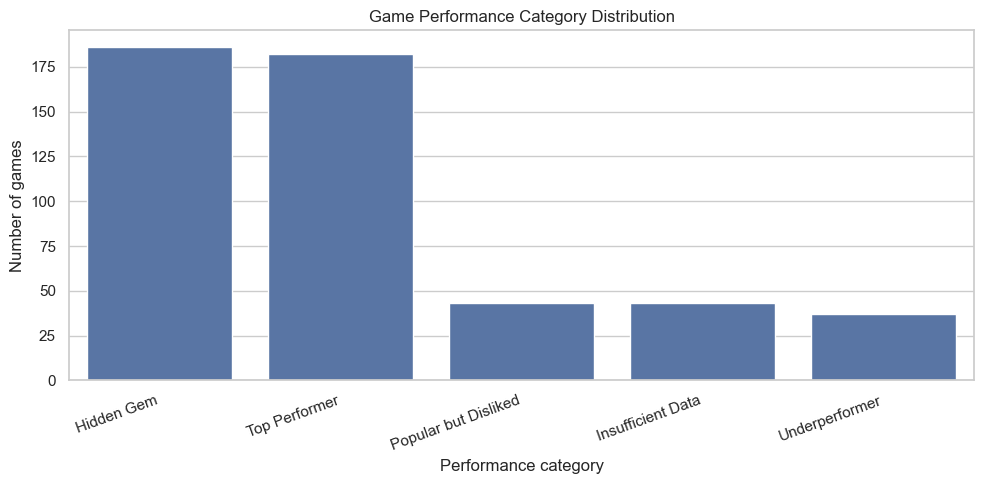

,metric,value
0,Number of games,440.000000
1,Overall positive review rate (%),91.581802
2,Median game price,9.990000
3,Median estimated owner midpoint,750000.000000
4,Median average playtime,217.000000


In [12]:
# Descriptive statistics
summary_statistics = df[
    ["price", "positive", "negative", "total_reviews",
     "positive_rate", "negative_rate", "average_playtime_forever",
     "estimated_owners_midpoint"]
].describe().T

display(summary_statistics)
summary_statistics.to_csv(REPORT_DIR / "steam_summary_statistics.csv")

# Performance category distribution
performance_counts = df["game_performance_category"].value_counts()
display(performance_counts.to_frame("game_count"))

plt.figure(figsize=(10, 5))
sns.countplot(data=df, x="game_performance_category")
plt.title("Game Performance Category Distribution")
plt.xlabel("Performance category")
plt.ylabel("Number of games")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(VIS_DIR / "game_performance_categories.png", dpi=300, bbox_inches="tight")
plt.show()

# Compact EDA report
eda_summary = pd.DataFrame({
    "metric": [
        "Number of games",
        "Overall positive review rate (%)",
        "Median game price",
        "Median estimated owner midpoint",
        "Median average playtime"
    ],
    "value": [
        df["name"].nunique(),
        overall_positive_rate,
        df["price"].median(),
        df["estimated_owners_midpoint"].median(),
        df["average_playtime_forever"].median()
    ]
})
display(eda_summary)
eda_summary.to_csv(REPORT_DIR / "steam_eda_summary.csv", index=False)
